In [6]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

n_rc=10
n_input_rows = n_rc  
n_input_columns = n_rc 
n_output_rows = n_rc  
n_output_columns = n_rc 
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -60. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.1 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 3. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.7 * nS 
g_AMPA_rec_E = 5.7 * nS 
g_AMPA_ext_I = 5.7 * nS
g_AMPA_rec_I = 5.7 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms



#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0


tau_HSP = 100*second           
target_rate = 2.0*Hz            
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3


kill_mask = np.ones(100, dtype=np.float32)
# kill_mask[np.array([range(45,47),range(35,37),range(55,57)]).flatten()]=0
# pen_idx = np.concatenate([range(24,28),[34,38,44,48,54,58],range(41,68)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[range(32,37)]=0 
kill_mask[35]=0 
pen_idx = np.concatenate([range(21,28),[31,38],range(41,48)])
far_idx = np.concatenate([range(1,18),range(71,99)])

# kill_mask[np.array([range(42,47),range(32,37)]).flatten()]=0
# pen_idx = np.concatenate([range(21,28),[31,38,41,48],range(51,58)])
# far_idx = np.concatenate([range(1,18),range(71,99)])

core_idx = np.where(kill_mask == 0)[0]          


def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA):
    # variables
    n_input_rows = 10  
    n_input_columns = 10 
    n_output_rows = 10 
    n_output_columns = 10 
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E  * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * k_AMPA_E_hsp  * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E * k_GABA_E_hsp * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dk_AMPA_E_hsp/dt = ((1 - k_AMPA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_ins_AMPA_E
                - (k_AMPA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_int_AMPA_E) : 1

    dk_GABA_E_hsp/dt = (-(k_GABA_E_hsp) * 1/(1+exp(-15*((target_rate - r_est)/target_rate-0.5))) / tau_int_GABA_E
                + (1 - k_GABA_E_hsp) * 1/(1+exp(-15*((r_est - target_rate)/target_rate-0.5))) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * 0.3 * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * 0.3 * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz


    dy_act / dt = -y_act / tau_active : 1
    '''


    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.k_AMPA_E_hsp = 0.35  
    P_E.k_GABA_E_hsp = 0.35  
    P_E.tau_ins_AMPA_E = tau_ins_AMPA   #50'000
    P_E.tau_int_AMPA_E = tau_int_AMPA   #5'000
    P_E.tau_ins_GABA_E = tau_ins_GABA   
    P_E.tau_int_GABA_E = tau_int_GABA  

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L

    P_E2 = NeuronGroup(N_E, eqs_E,threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler',name='P_E2')
    P_E2.v = V_L
    P_E2.k_AMPA_E_hsp = 0.5
    P_E2.k_GABA_E_hsp = 0.3

    P_E2.tau_ins_AMPA_E = tau_ins_AMPA
    P_E2.tau_int_AMPA_E = tau_int_AMPA
    P_E2.tau_ins_GABA_E = tau_ins_GABA
    P_E2.tau_int_GABA_E = tau_int_GABA


    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    
    C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
        s_AMPA_ext += w  
        ''', method='euler', name='PG_E')
    C_PG_E.connect(j='i')  

    
    C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
        s_AMPA += w  
        ''', method='euler', name='E_E')
    recurrent_radius = 2
    for y1 in range(n_output_rows):
        for x1 in range(n_output_columns):
            post = y1 * n_output_columns + x1
            for dy in range(-recurrent_radius, recurrent_radius + 1):
                for dx in range(-recurrent_radius, recurrent_radius + 1):
                    if dx == 0 and dy == 0:
                        continue
                    x2 = x1 + dx
                    y2 = y1 + dy
                    if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                        pre = y2 * n_output_columns + x2
                        C_E_E.connect(i=pre, j=post)
    C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
    s_AMPA += w
    ''', method='euler', name='E_I') #        x_postE_post += 1.0 
    C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
    for inh_idx, (ix, iy) in enumerate(inh_positions):
        for ex_y in range(n_output_rows):
            for ex_x in range(n_output_columns):
                if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                    exc_idx = ex_y * n_output_columns + ex_x
                    C_I_E.connect(i=inh_idx, j=exc_idx)
                    C_E_I.connect(i=exc_idx, j=inh_idx)
    C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
    for iy in range(n_inh_rows):
        for ix in range(n_inh_cols):
            post = iy * n_inh_cols + ix
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    if dx == 0 and dy == 0:
                        continue
                    x2, y2 = ix + dx, iy + dy
                    if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                        pre = y2 * n_inh_cols + x2
                        C_I_I.connect(i=pre, j=post)

    C_E_E2 = Synapses(P_E, P_E2,model='w:1', on_pre='s_AMPA_post += w', method='euler', name='E_E2')
    C_E_E2.connect(p=0.2)  
    C_E_E2.w[:] = 0.5#np.clip(np.random.normal(0.8, 0.05, len(C_E_E2.w)), 0.0, 1.0)
    C_E2_E2 = Synapses(P_E2, P_E2, model='w:1',on_pre='s_AMPA_post += w', method='euler', name='E2_E2')
    C_E2_E2.connect(p=0.8, condition='i!=j') 
    C_E2_E2.w[:] = np.clip(np.random.normal(loc=0.70, scale=0.05, size=len(C_E2_E2.w)), 0.0, 1.0)

    C_PG_E.w[:] = 1.2 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
    C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
    C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
    C_E_I.w[:] = 0.6#np.clip(np.random.normal(loc=0.40, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
    C_E_E.w[:] = np.clip(np.random.normal(loc=0.44, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    rate_core = NeuronGroup(1, 'r_core : Hz', method='euler', name='rate_core')
    rate_pen  = NeuronGroup(1, 'r_pen  : Hz', method='euler', name='rate_pen')
    rate_far  = NeuronGroup(1, 'r_far  : Hz', method='euler', name='rate_far')
    # Core
    C_r_core = Synapses(
        P_E, rate_core,
        model=''' N_core : 1
        r_core_post = r_est_pre / N_core : Hz (summed)''',
        method='euler',
        name='C_r_core'
    )
    C_r_core.connect(i=core_idx, j=0)
    C_r_core.N_core = len(core_idx)
    # Penumbra
    C_r_pen = Synapses(
        P_E, rate_pen,
        model='''N_pen : 1
        r_pen_post = r_est_pre / N_pen : Hz (summed)''',
        method='euler',
        name='C_r_pen'
    )
    C_r_pen.connect(i=pen_idx, j=0)
    C_r_pen.N_pen= len(pen_idx)
    # Far
    C_r_far = Synapses(
        P_E, rate_far,
        model='''N_far : 1
        r_far_post = r_est_pre / N_far : Hz (summed)''',
        method='euler',
        name='C_r_far'
    )
    C_r_far.connect(i=far_idx, j=0)
    C_r_far.N_far=len(far_idx)
    
    rate_core_mon = StateMonitor(rate_core, 'r_core', record=True, dt=record_dt, name='rate_core_mon')
    rate_pen_mon  = StateMonitor(rate_pen,  'r_pen',  record=True, dt=record_dt, name='rate_pen_mon')
    rate_far_mon  = StateMonitor(rate_far,  'r_far',  record=True, dt=record_dt, name='rate_far_mon')
    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'k_AMPA_E_hsp', record=True, dt=record_dt, name='k_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'k_GABA_E_hsp', record=True, dt=record_dt, name='k_GABA_E_hsp')

    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_E2 = SpikeMonitor(P_E2, name = 'sp_exc2')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=40, scale=3, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')



def run_sim(tau_ins_AMPA,tau_int_AMPA,tau_ins_GABA,tau_int_GABA,show_time = 1000*ms):
    net = build_network(tau_ins_AMPA=tau_ins_AMPA,tau_int_AMPA=tau_int_AMPA,tau_ins_GABA=tau_ins_GABA,tau_int_GABA=tau_int_GABA)
    show_rand_rate(net,show_time=show_time)
    return net



Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([47.03533925, 39.6754701 , 37.31287094, ..., 40.53177343,
       37.71198347, 40.99943066]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 3. ks
75.832 s (2%) simulated in 10s, estimated 6m 26s remaining.
150.344 s (5%) simulated in 20s, estimated 6m 19s remaining.
221.162 s (7%) simulated in 30s, estimated 6m 17s remaining.
292.577 s (9%) simulated in 40s, estimated 6m 10s remaining.
0.360231 ks (12%) simulated in 50s, estimated 6m 6s remaining.
0.43203 ks (14%) simulated in 1m 0s, estimated 5m 57s remaining.
0.506416 ks (16%) simulated in 1m 10s, estimated 5m 45s remaining.
0.583658 ks (19%) simulated in 1m 20s, estimated 5m 31s remaining.
0.632925 ks (21%) simulated in 1m 30s, estimated 5m 37s remaining.
0.698401 ks (23%) simulated in 1m 40s, estimated 5m 30s remaining.
0.767943 ks (25%) simulated in 1m 50s, estimated 5m 20s remaining.
0.838807 ks (27%) simulated in 2m 0s, estimated 5m 9s remaining.
0.909471 ks (30%) simulated in 2m 10s, estimated 4m 59s remaining.
0.980001 ks (32%) simulated in 2m 20s, estimated 4m 49s remaining.
1.051111 ks (35%) simulated in 2m 30s, es

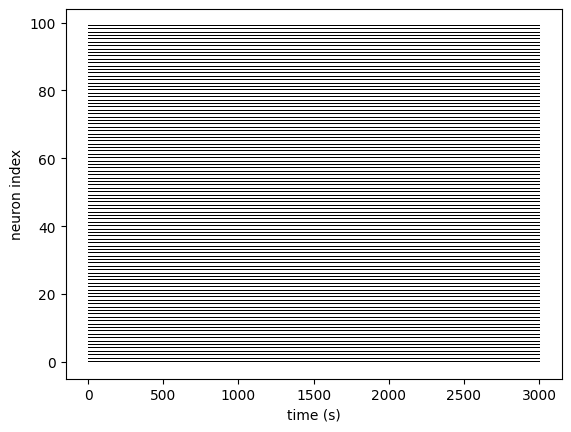

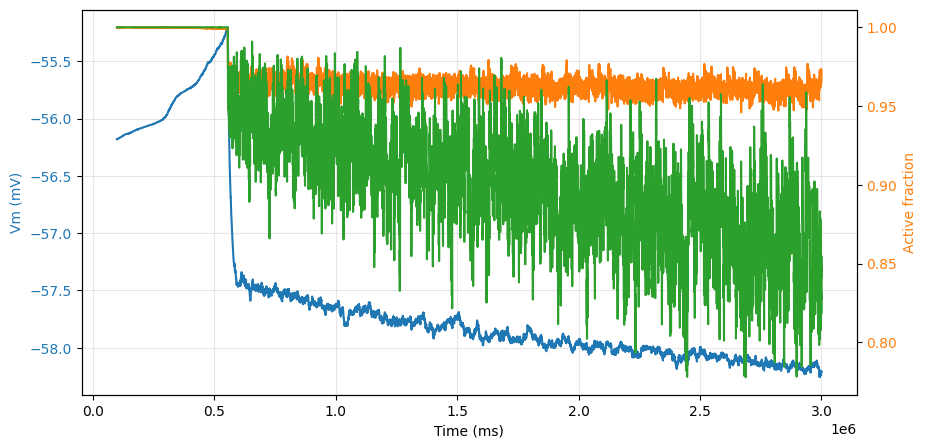

In [7]:
start_scope()
defaultclock.dt = 1000 * us
net = run_sim(tau_ins_AMPA=5000*second,
              tau_int_AMPA=5000*second,
              tau_ins_GABA=5000*second,
              tau_int_GABA=5000*second,
              show_time=3000*second)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spE2 = net['sp_exc2']
spI = net['sp_inh']
#plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')
plot_raster(spE2.i, spE2.t, time_unit=second, marker=',', color='k')


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

# fig.tight_layout()
# plt.show()

# figure(figsize=(10, 6))
# plot(spE.t/ms*1000, spE.i, ',b', label='Excitatory main')
# plot(spE2.t/ms*1000, spE2.i + 100, ',r', label='Excitatory 2')
# xlabel('Time (s)')
# ylabel('Neuron Index')
# legend(loc='upper right')
# title('Raster Plot: Two Populations')
# show()

<Axes: xlabel='time (s)', ylabel='neuron index'>

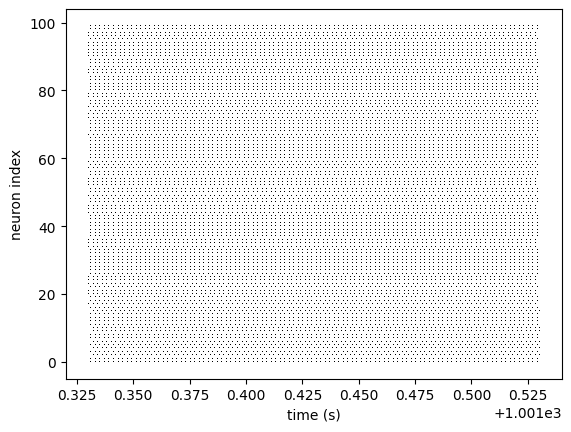

In [9]:
plot_raster(spE2.i[int(5*10**7):int(5.001*10**7)], spE2.t[int(5*10**7):int(5.001*10**7)], time_unit=second, marker=',', color='k')
